# Eerste MX-experiment: alleen gewichten

**MXFP6 E2M3 / A32, blokgrootte 32.** Dit notebook leest uitsluitend opgeslagen gegevens.
Geen training, modelcalls, herkalibratie of downloads. De bron is de eerder getrainde SVHN-train-only-referentie.

De eerste proef is **directe conversie van een bestaand checkpoint**, niet QAT.
Gewichtsquantisatie is nieuw; de tanh/normalisatie van het oorspronkelijke W32-pad, A32/ReLU en BN32 blijven behouden.
Beste en laatste checkpoint blijven geselecteerd volgens de oude no-MX-run.

In [1]:
from pathlib import Path
RUN_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_weights_step1\\20261016_200801_390866_evaluate')


In [2]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
report = json.loads((RUN_DIR / 'run_report.json').read_text(encoding='utf-8'))
assert report['command'] == 'evaluate', 'Open de notebook uit de evaluate-map, niet de check-map.'
metrics = pd.read_csv(RUN_DIR / 'metrics.csv')
layers = pd.read_csv(RUN_DIR / 'layer_metrics.csv')
assert report['optimizer_steps'] == 0
assert report['config']['activations'] == 'original_A32_ReLU'
assert report['config']['weight_format'] == 'MXFP6_E2M3'
if report.get('synthetic_fixture_only', False):
    display(Markdown('## SYNTHETISCHE SOFTWARETEST - GEEN SVHN-RESULTATEN'))
display(Markdown('**Rapportstatus: ' + report['status'] + '**'))
if report['status'] != 'PASS':
    display(Markdown('**Eerst de afwijkende controles beoordelen; geen MX-conclusie trekken.**'))
display(pd.DataFrame([report['config']]).T.rename(columns={0:'Instelling'}))

**Rapportstatus: PASS**

,Instelling
weight_format,MXFP6_E2M3
local_exponent_bits,2
mantissa_bits,3
local_bias,1
block_size,32
scale_format,E8M0
scale_rule,paper_algorithm1_floor_log2_amax_minus_2; clip...
layout,output_channel_rows; flatten_Cin_Kh_Kw; traili...
rounding,nearest_ties_to_even; saturate
input_fp32_subnormals,flush_to_signed_zero


## Vier paden, hetzelfde checkpoint

`reference_W32_A32`: oorspronkelijke code. `wrapper_MX_off_A32`: nieuwe adapter met MX uit.
`MXFP6_E2M3_A32`: MX aan. `stored_MXFP6_E2M3_A32`: herladen broncodes.

De twee middelste controleverschillen horen numeriek verwaarloosbaar te zijn en mogen de voorspellingen niet wijzigen.
Het verschil **MX versus reference** is de gemeten directe conversiegevoeligheid; niet het resultaat na MX-training.

In [3]:
display(metrics[['role','epoch','mode','n','correct1','count_top1_percent','hard_cross_entropy']])
wide = metrics.pivot(index=['role','epoch'],columns='mode',values='count_top1_percent')
wide['MX_minus_reference_pp'] = wide['MXFP6_E2M3_A32'] - wide['reference_W32_A32']
display(wide)


,role,epoch,mode,n,correct1,count_top1_percent,hard_cross_entropy
0,best,54,reference_W32_A32,26032,24716,94.944683,0.193091
1,best,54,wrapper_MX_off_A32,26032,24716,94.944683,0.193091
2,best,54,MXFP6_E2M3_A32,26032,24720,94.960049,0.193807
3,best,54,stored_MXFP6_E2M3_A32,26032,24720,94.960049,0.193807
4,last,100,reference_W32_A32,26032,24675,94.787185,0.194407
5,last,100,wrapper_MX_off_A32,26032,24675,94.787185,0.194407
6,last,100,MXFP6_E2M3_A32,26032,24660,94.729564,0.194495
7,last,100,stored_MXFP6_E2M3_A32,26032,24660,94.729564,0.194495


,mode,MXFP6_E2M3_A32,reference_W32_A32,stored_MXFP6_E2M3_A32,wrapper_MX_off_A32,MX_minus_reference_pp
role,epoch,,,,,
best,54,94.960049,94.944683,94.960049,94.944683,0.015366
last,100,94.729564,94.787185,94.729564,94.787185,-0.057621


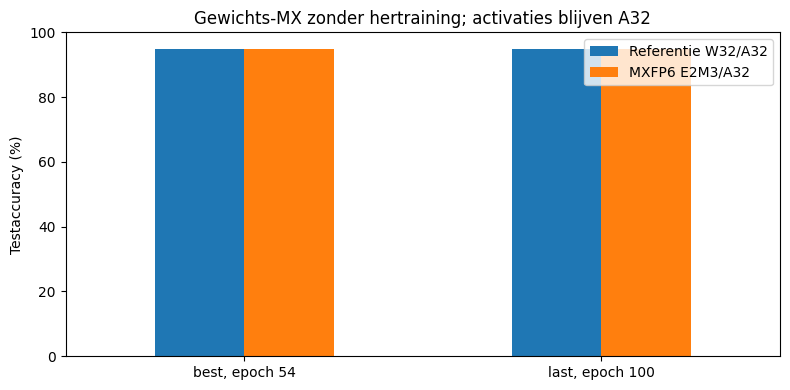

In [4]:
pair = wide[['reference_W32_A32','MXFP6_E2M3_A32']].copy()
pair.index = [f'{role}, epoch {epoch}' for role,epoch in pair.index]
ax = pair.plot.bar(figsize=(8,4),rot=0)
ax.set_ylabel('Testaccuracy (%)')
ax.set_ylim(0,100)
ax.set_title('Gewichts-MX zonder hertraining; activaties blijven A32')
ax.legend(['Referentie W32/A32','MXFP6 E2M3/A32'])
plt.tight_layout()
plt.show()


## Invarianties en afwijkingen

De runner rapporteert exacte logitsgelijkheid en een afzonderlijke numerieke tolerantiecontrole.
Het aantal correcte voorspellingen van de no-MX-hermeting moet overeenkomen met het broncheckpoint.
Een andere score is eerst een reproduceerbaarheidsvraag, geen effect van MX.

In [5]:
display(pd.DataFrame(report['checks']).T)
display(Markdown('### Waarschuwingen'))
display(report.get('warnings', []))


,epoch,checkpoint_unchanged,reference_counts_match,expected_correct1,quantized_weight_tensors_exact,control_logits_exact,control_logits_close,control_predictions_equal,export_logits_exact,export_logits_close,export_predictions_equal,control_max_abs_logit_difference,export_max_abs_logit_difference,MX_vs_reference_prediction_changes,test_seconds_all_four_paths_including_instrumentation,source_export,no_master_for_encoded_layers_in_export,auxiliary_state_bytes
best,54,True,True,24716,True,True,True,True,True,True,True,0.0,0.0,100,7.639189,"{'file': 'mx_source_best.pt', 'sha256': 'd69ce...",True,19248
last,100,True,True,24675,True,True,True,True,True,True,True,0.0,0.0,129,7.565933,"{'file': 'mx_source_last.pt', 'sha256': 'b86b4...",True,19248


### Waarschuwingen

["The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\\actions-runner\\_work\\pytorch\\pytorch\\pytorch\\aten\\src\\ATen\\native\\Memory.cpp:48.)",
 "The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\\actions-runner\\_work\\pytorch\\pytorch\\pytorch\\aten\\src\\ATen\\native\\Memory.cpp:33.)"]

## Lokale quantisatiefout en code-opslag

MAE/RMSE vergelijken de gedecodeerde MX-gewichten met de EFFECTIEVE W32-gewichten, niet met de onbewerkte master.
`new_zero_count` telt niet-nulbronnen die nul worden. `local_subnormal_count` betreft E2M3-subnormals.
Schaalclipping en subnormale FP32-bronnen worden apart gerapporteerd.

In [6]:
display(layers)
storage = layers.groupby(['role','epoch'])[['n_weights','padded_slots','packed_weight_and_scale_bytes','fp32_weight_bytes']].sum()
storage['auxiliary_state_bytes'] = [report['checks'][role]['auxiliary_state_bytes'] for role,epoch in storage.index]
storage['payload_bytes_including_auxiliary'] = storage['packed_weight_and_scale_bytes'] + storage['auxiliary_state_bytes']
display(storage)


,layer,n_weights,blocks,padded_slots,mae,rmse,max_abs_error,relative_l2,new_zero_count,local_subnormal_count,out_of_element_range_before_round,fp32_subnormal_input_count,scale_range_clamped_blocks,scale_exponent_min,scale_exponent_max,packed_weight_and_scale_bytes,fp32_weight_bytes,role,epoch
0,layers.3,1728,64,320,0.002045,0.002778,0.007789,0.024907,143,272,0,0,0,-5,-5,1600,6912,best,54
1,layers.6,2304,80,256,0.002074,0.002746,0.007811,0.025530,277,375,0,0,0,-5,-5,2000,9216,best,54
2,layers.10,4608,160,512,0.001865,0.002508,0.007810,0.024133,482,868,0,0,0,-5,-5,4000,18432,best,54
3,layers.13,9216,288,0,0.002358,0.003249,0.007812,0.031757,750,1961,0,0,0,-5,-5,7200,36864,best,54
4,layers.16,9216,288,0,0.002292,0.003098,0.007811,0.031134,754,2284,0,0,0,-5,-5,7200,36864,best,54
5,layers.20,102400,3200,0,0.001158,0.001651,0.007811,0.029766,4333,35274,290,0,0,-9,-5,80000,409600,best,54
6,layers.3,1728,64,320,0.001413,0.002150,0.007791,0.018938,186,227,0,0,0,-5,-5,1600,6912,last,100
7,layers.6,2304,80,256,0.001352,0.002083,0.007758,0.019077,352,303,0,0,0,-5,-5,2000,9216,last,100
8,layers.10,4608,160,512,0.001982,0.002551,0.007784,0.024074,635,722,0,0,0,-5,-5,4000,18432,last,100
9,layers.13,9216,288,0,0.002586,0.003506,0.007812,0.033482,1053,1654,0,0,0,-5,-5,7200,36864,last,100


,,n_weights,padded_slots,packed_weight_and_scale_bytes,fp32_weight_bytes,auxiliary_state_bytes,payload_bytes_including_auxiliary
role,epoch,,,,,,
best,54,129472,1088,102000,517888,19248,121248
last,100,129472,1088,102000,517888,19248,121248


**Geen hardwareclaim:** de MX-export bevat 24 codebytes + 1 schaalbyte per 32 gewichten, plus padding en aanvullende staat.
De bestandsheader en de FP32-rekenbuffers van de emulator zijn andere grootheden.
Deze meting bewijst geen native 6-bitversnelling, energiewinst, trainingsconvergentie of truncatierobuustheid.

Bronnen: auteurscode in de bijgeleverde bron-ZIP; projectpaper *Microscaling Data Formats for Deep Learning*, p. 2-4, tabel 1/Algorithm 1;
OCP MX-specificatie v1.0 (2023), p. 11-14. De experimentele keuzes staan in `CODEWIJZIGINGEN.md`.